# Financial Fraud Detection — Model Development Notebook

**Project scope note (read first):** This notebook implements a deliberately scoped-down
version of the *Financial Fraud Detection Model with Dashboard* SRS (v1.0, 10 Sep 2026).

The full SRS describes a production system with streaming ingestion (Kafka/Spark), a live
FastAPI scoring service, a Streamlit dashboard, external email alerting, and multi-role
authentication. **None of that is in scope here.** This project works with a single static,
already-cleaned CSV of 5,000 transactions and focuses on three deliverables:

1. **This notebook** — EDA, feature engineering, model comparison (Logistic Regression,
   Random Forest, XGBoost), and evaluation against the SRS's proposed quality gate (ML03).
2. **An interactive Power BI dashboard** — built from the scored CSV this notebook exports
   (`scored_transactions.csv`), covering the KPI/overview and investigation views described
   in UI01–UI02, adapted for static (non-live) data.
3. **A written report** — problem framing, methodology, results, and explicitly documented
   deviations from the original SRS scope (out: Kafka, Spark, blockchain, mobile, banking
   adapters, live streaming, email delivery, multi-tenant auth).

Requirements kept in spirit from the SRS even though the system is static:
- **ML01** — no identifiers, labels, or outcome fields used as predictors; only pre-event
  information is used.
- **ML02** — chronological train/validation/test split (not random) so the model is never
  evaluated on transactions that occurred before ones it was trained on... in reverse.
- **ML03** — evaluation reports precision, recall, F1, PR AUC, ROC AUC, and confusion matrix,
  not accuracy alone, and is checked against the proposed MVP gate (recall ≥ 80%, precision ≥ 30%).
- **ML04** — a 0–1 risk score with Low / Medium / High bands (<0.40 / 0.40–0.70 / ≥0.70).


## 1. Imports and setup

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, precision_recall_curve,
    roc_curve, classification_report
)
from xgboost import XGBClassifier

import plotly.express as px
import plotly.graph_objects as go
import plotly.figure_factory as ff
import plotly.io as pio
pio.renderers.default = "notebook_connected"  # loads plotly.js from CDN -> keeps file size small
                                                # (requires internet access when you open/view the notebook)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


## 2. Load data

In [ ]:
df = pd.read_csv("financial_fraud_detection_dataset.csv")
df["Transaction_Date"] = pd.to_datetime(df["Transaction_Date"], format="%d-%m-%Y %H:%M")
df = df.sort_values("Transaction_Date").reset_index(drop=True)

print(f"Rows: {len(df):,}  |  Columns: {df.shape[1]}")
print(f"Date range: {df['Transaction_Date'].min()}  to  {df['Transaction_Date'].max()}")
df.head()


Rows: 5,000  |  Columns: 14
Date range: 2023-01-01 02:16:00  to  2024-02-21 15:34:00


,Transaction_ID,Customer_ID,Transaction_Date,Transaction_Amount,Merchant_Category,Payment_Method,Device_Type,Location,Is_International,Previous_Transactions,Average_Spend,Account_Age_Days,Suspicious_Keyword,Fraudulent
0,T103438,CUST3131,2023-01-01 02:16:00,210.69,Grocery,PayPal,Desktop,Hyderabad,0,69,450.90,1824,Yes,0
1,T104159,CUST6885,2023-01-01 05:46:00,66.73,Entertainment,Debit Card,Desktop,Hyderabad,1,50,421.59,79,No,0
2,T102971,CUST1470,2023-01-01 09:06:00,14.24,Utilities,Debit Card,POS,Pune,0,82,472.06,790,No,0
3,T102322,CUST6619,2023-01-01 11:34:00,74.90,Fashion,Debit Card,Desktop,Hyderabad,0,152,236.30,388,Yes,0
4,T104734,CUST6625,2023-01-01 11:41:00,45.04,Grocery,NetBanking,POS,Chennai,0,76,173.08,1300,No,0


In [ ]:
df.info()
print()
print("Missing values per column:")
print(df.isna().sum())


<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   Transaction_ID         5000 non-null   str           
 1   Customer_ID            5000 non-null   str           
 2   Transaction_Date       5000 non-null   datetime64[us]
 3   Transaction_Amount     5000 non-null   float64       
 4   Merchant_Category      5000 non-null   str           
 5   Payment_Method         5000 non-null   str           
 6   Device_Type            5000 non-null   str           
 7   Location               5000 non-null   str           
 8   Is_International       5000 non-null   int64         
 9   Previous_Transactions  5000 non-null   int64         
 10  Average_Spend          5000 non-null   float64       
 11  Account_Age_Days       5000 non-null   int64         
 12  Suspicious_Keyword     5000 non-null   str           
 13  Fraudulent    

## 3. Exploratory data analysis

### 3.1 Class balance


Legitimate: 4,518  |  Fraud: 482  |  Fraud rate: 9.64%


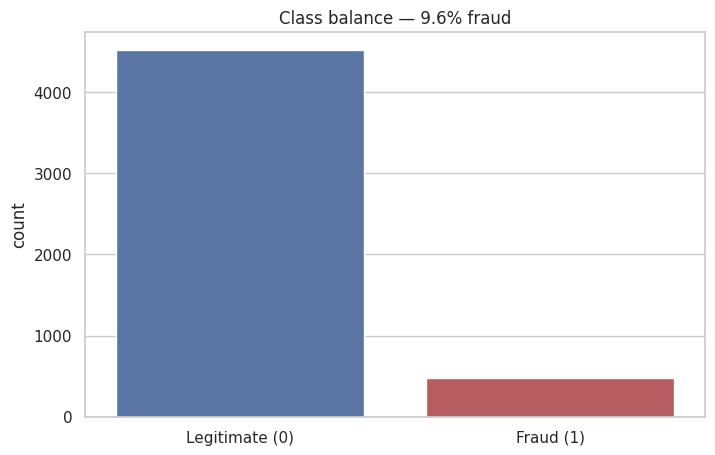

In [ ]:
fraud_counts = df["Fraudulent"].value_counts().sort_index()
fraud_rate = df["Fraudulent"].mean()
print(f"Legitimate: {fraud_counts[0]:,}  |  Fraud: {fraud_counts[1]:,}  |  Fraud rate: {fraud_rate:.2%}")

fig, ax = plt.subplots()
sns.countplot(x="Fraudulent", data=df, ax=ax, palette=["#4C72B0", "#C44E52"])
ax.set_xticklabels(["Legitimate (0)", "Fraud (1)"])
ax.set_title(f"Class balance — {fraud_rate:.1%} fraud")
ax.set_xlabel("")
plt.show()


This is a strongly imbalanced problem (~1 fraud case per ~10 legitimate transactions), consistent with real-world fraud rates. This shapes model choice (class weighting) and metric choice (precision/recall/PR-AUC rather than accuracy — per SRS ML03).

### 3.2 Transaction amount by class

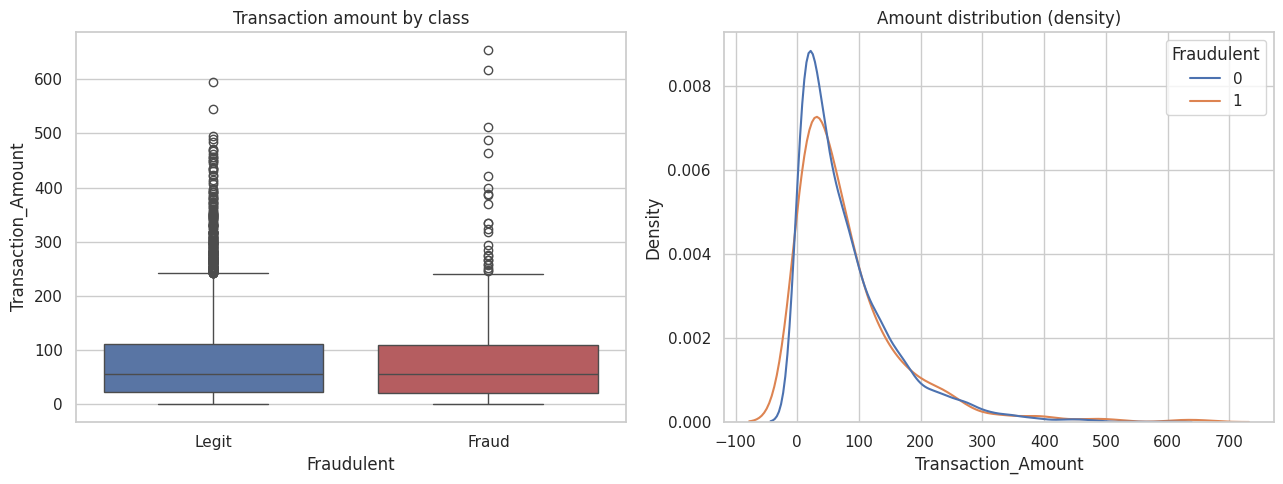

,count,mean,std,min,25%,50%,75%,max
Fraudulent,,,,,,,,
0,4518.0,78.880558,77.776372,0.0,22.635,55.455,110.3725,595.34
1,482.0,81.993693,89.373791,0.0,21.490,55.430,109.2900,653.80


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(x="Fraudulent", y="Transaction_Amount", data=df, ax=axes[0], palette=["#4C72B0", "#C44E52"])
axes[0].set_xticklabels(["Legit", "Fraud"])
axes[0].set_title("Transaction amount by class")

sns.kdeplot(data=df, x="Transaction_Amount", hue="Fraudulent", ax=axes[1], common_norm=False)
axes[1].set_title("Amount distribution (density)")
plt.tight_layout()
plt.show()

df.groupby("Fraudulent")["Transaction_Amount"].describe()


### 3.3 Fraud rate by categorical features

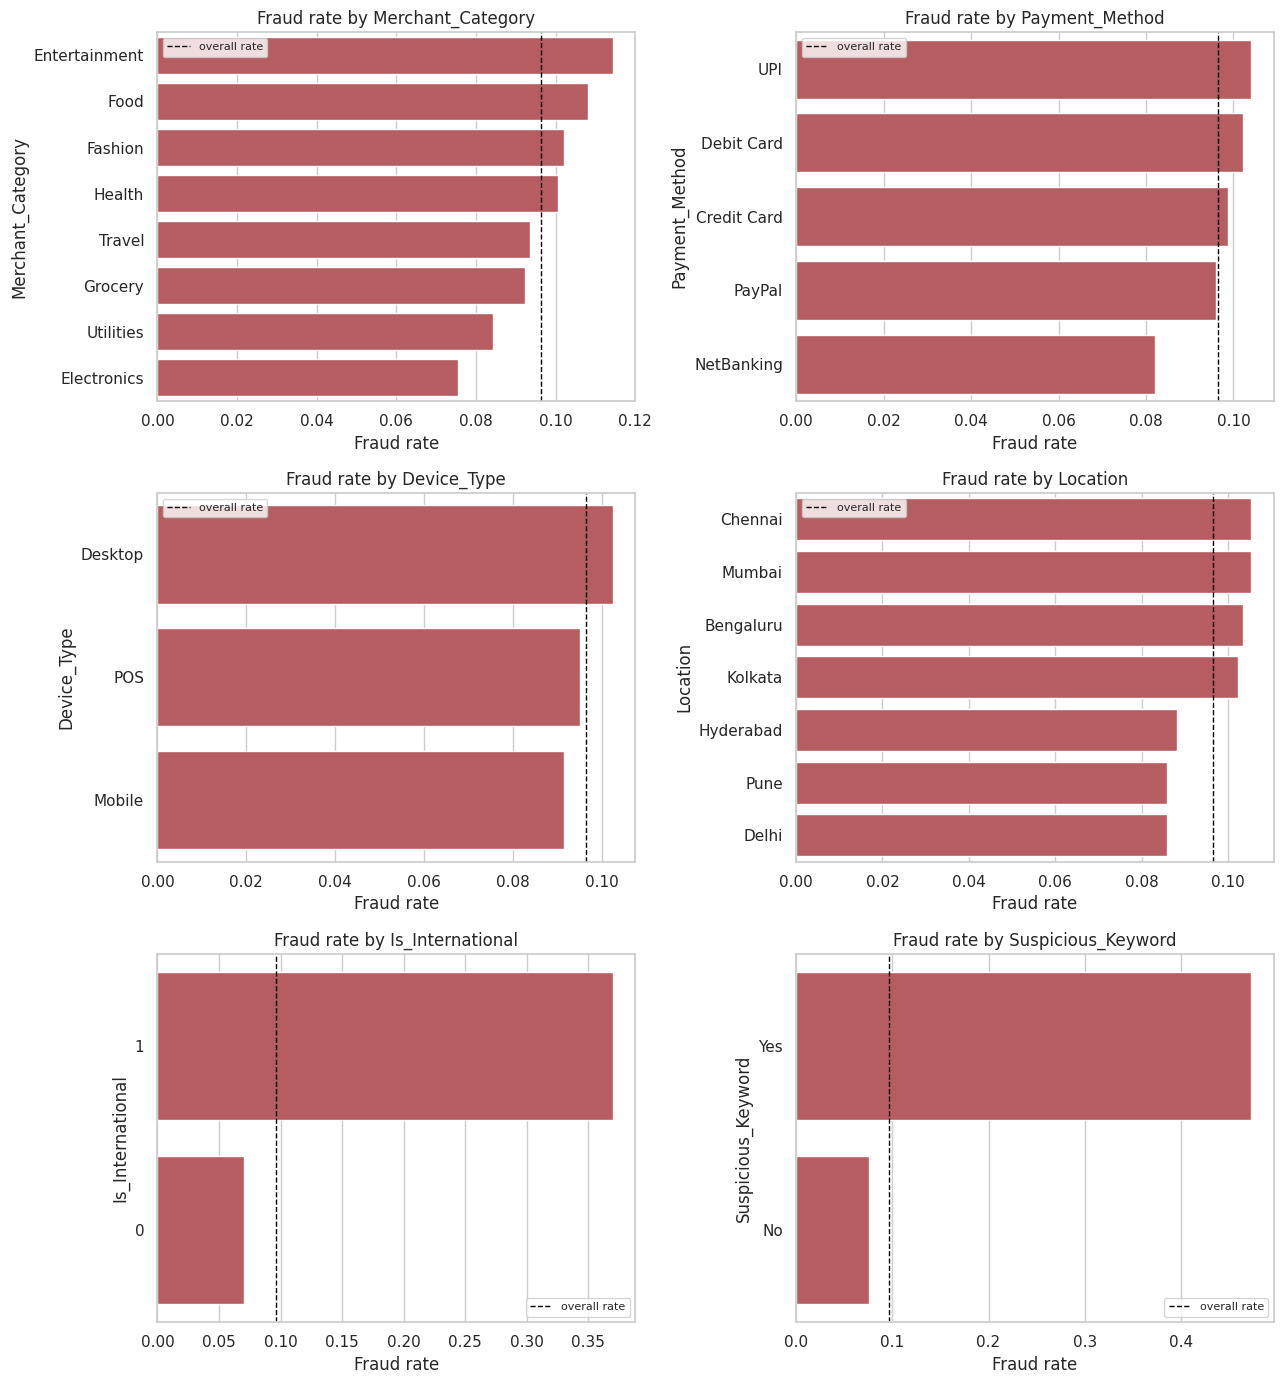

In [ ]:
cat_cols = ["Merchant_Category", "Payment_Method", "Device_Type", "Location",
            "Is_International", "Suspicious_Keyword"]

fig, axes = plt.subplots(3, 2, figsize=(13, 14))
axes = axes.flatten()
for i, col in enumerate(cat_cols):
    rate = df.groupby(col)["Fraudulent"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index.astype(str), ax=axes[i], color="#C44E52")
    axes[i].axvline(fraud_rate, color="black", linestyle="--", linewidth=1, label="overall rate")
    axes[i].set_title(f"Fraud rate by {col}")
    axes[i].set_xlabel("Fraud rate")
    axes[i].legend(fontsize=8)
plt.tight_layout()
plt.show()


### 3.4 Fraud rate over time (hour of day, day of week)

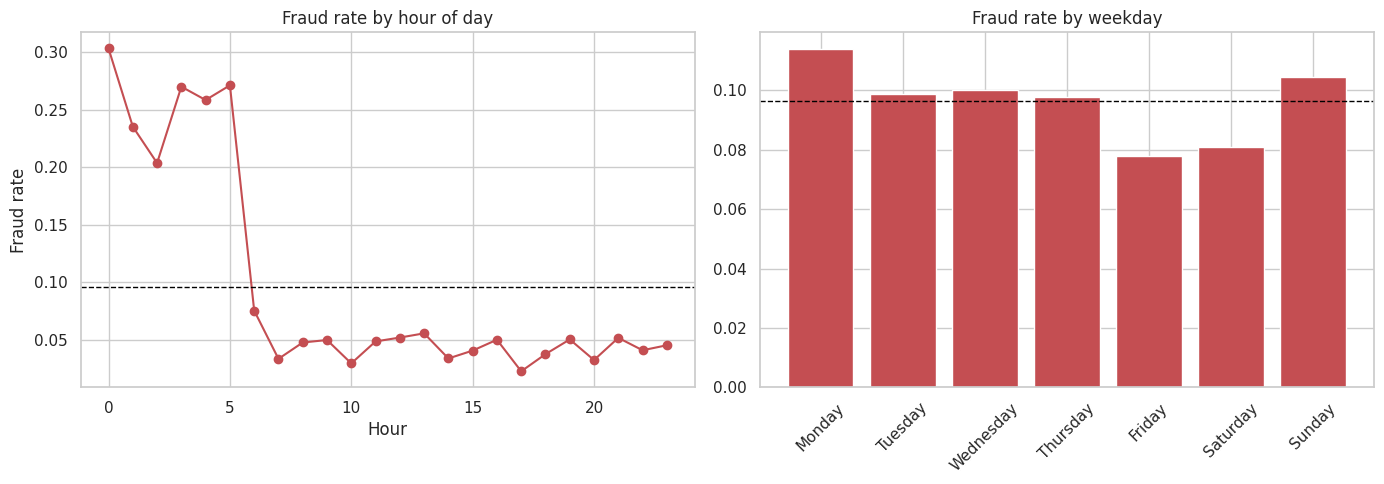

In [ ]:
df["hour"] = df["Transaction_Date"].dt.hour
df["weekday"] = df["Transaction_Date"].dt.day_name()
weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
hour_rate = df.groupby("hour")["Fraudulent"].mean()
axes[0].plot(hour_rate.index, hour_rate.values, marker="o", color="#C44E52")
axes[0].axhline(fraud_rate, color="black", linestyle="--", linewidth=1)
axes[0].set_title("Fraud rate by hour of day")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Fraud rate")

wd_rate = df.groupby("weekday")["Fraudulent"].mean().reindex(weekday_order)
axes[1].bar(wd_rate.index, wd_rate.values, color="#C44E52")
axes[1].axhline(fraud_rate, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Fraud rate by weekday")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()


### 3.5 Correlation among numeric features

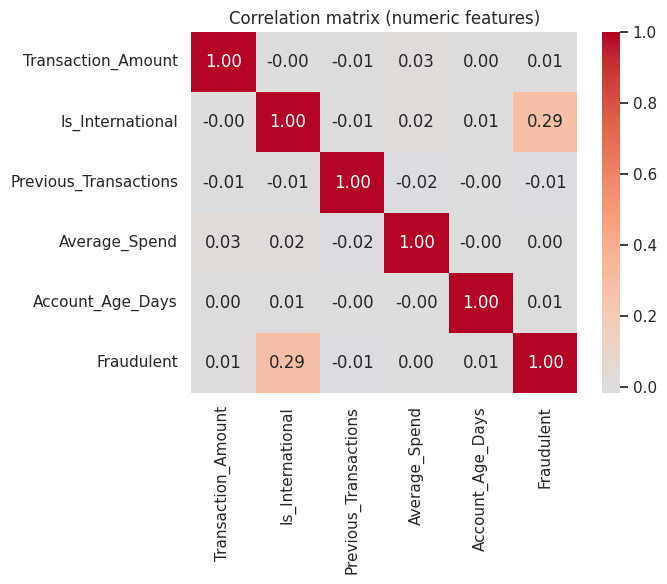

In [ ]:
numeric_cols = ["Transaction_Amount", "Is_International", "Previous_Transactions",
                 "Average_Spend", "Account_Age_Days", "Fraudulent"]
corr = df[numeric_cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation matrix (numeric features)")
plt.tight_layout()
plt.show()


## 3.6 Extended visualization gallery (26 chart types)

You asked for the following chart types added to EDA — note your list actually has **26**
distinct entries (Bar → Confusion Matrix), not 15; all 26 are implemented below rather than
truncating the list. Charts 1–23 use only the raw transaction data and sit here in the EDA
section. Charts 24–26 (ROC curve, Precision-Recall curve, Confusion matrix) need a trained
model's predictions, so they're built later, in Section 9, right after the model is evaluated
— each one is numbered to match this list so you can find it.

All charts use **Plotly** for interactivity (hover for exact values, zoom, pan, click a legend
entry to isolate a series). Plotly loads its JS library from a CDN (`notebook_connected` mode)
to keep this file small — that means an internet connection is needed the first time you open
the notebook and view these cells.

**On "animated":** five chart types below are genuinely frame-by-frame animated (with a
Play button and a slider) because Plotly's animation model only applies naturally to
bar/scatter/line/histogram-style traces over a category or time dimension — chart types
**1 (Bar), 7 (Line), 9 (Histogram), 12 (Scatter) and 13 (Bubble)**. The rest render as rich,
interactive single-view charts (hover/zoom/click), since frame-by-frame animation doesn't have
a natural meaning for e.g. a single pie, treemap, or gauge.


In [ ]:
df["Fraud_Status"] = df["Fraudulent"].map({0: "Legitimate", 1: "Fraud"})
df["month"] = df["Transaction_Date"].dt.to_period("M").astype(str)


### 1. Bar Chart (animated) — compare categories\nTransaction count by merchant category, animated frame-by-frame across weekday.

In [ ]:
cat_wd = df.groupby(["weekday", "Merchant_Category"]).size().reset_index(name="count")
fig = px.bar(cat_wd, x="Merchant_Category", y="count", color="Merchant_Category",
             animation_frame="weekday", category_orders={"weekday": weekday_order},
             range_y=[0, cat_wd["count"].max() * 1.15],
             title="1. Bar Chart (animated) — transaction count by merchant category, by weekday")
fig.update_layout(showlegend=False)
fig.show()


### 2. Horizontal Bar Chart — compare many categories\nFraud rate by location.

In [ ]:
loc_rate = df.groupby("Location")["Fraudulent"].mean().sort_values().reset_index()
fig = px.bar(loc_rate, x="Fraudulent", y="Location", orientation="h",
             labels={"Fraudulent": "Fraud rate"}, color="Fraudulent", color_continuous_scale="Reds",
             title="2. Horizontal Bar Chart — fraud rate by location")
fig.show()


### 3. Stacked Bar Chart — compare multiple groups\nLegitimate vs. fraud count by payment method.

In [ ]:
pm = df.groupby(["Payment_Method", "Fraud_Status"]).size().reset_index(name="count")
fig = px.bar(pm, x="Payment_Method", y="count", color="Fraud_Status", barmode="stack",
             title="3. Stacked Bar Chart — legitimate vs. fraud count by payment method")
fig.show()


### 4. Grouped Bar Chart — compare categories side-by-side\nFraud rate by device type, domestic vs. international.

In [ ]:
dev = df.groupby(["Device_Type", "Is_International"])["Fraudulent"].mean().reset_index()
dev["Is_International"] = dev["Is_International"].map({0: "Domestic", 1: "International"})
fig = px.bar(dev, x="Device_Type", y="Fraudulent", color="Is_International", barmode="group",
             labels={"Fraudulent": "Fraud rate"},
             title="4. Grouped Bar Chart — fraud rate by device type, domestic vs. international")
fig.show()


### 5. Pie Chart — show percentage/proportion\nShare of transactions by merchant category.

In [ ]:
mc = df["Merchant_Category"].value_counts().reset_index()
mc.columns = ["Merchant_Category", "count"]
fig = px.pie(mc, names="Merchant_Category", values="count",
             title="5. Pie Chart — share of transactions by merchant category")
fig.show()


### 6. Donut Chart — alternative to pie chart\nShare of transactions by payment method.

In [ ]:
pmc = df["Payment_Method"].value_counts().reset_index()
pmc.columns = ["Payment_Method", "count"]
fig = px.pie(pmc, names="Payment_Method", values="count", hole=0.5,
             title="6. Donut Chart — share of transactions by payment method")
fig.show()


### 7. Line Chart (animated) — show trends over time\nCumulative transaction count, revealed day by day.

In [ ]:
daily = df.groupby(df["Transaction_Date"].dt.date).size().reset_index(name="count")
daily.columns = ["date", "count"]
daily["cum_count"] = daily["count"].cumsum()

step = 5  # reveal every 5 days to keep the animation snappy
frame_idx = list(range(1, len(daily), step)) + [len(daily)]
frames = [go.Frame(data=[go.Scatter(x=daily["date"][:k], y=daily["cum_count"][:k], mode="lines",
                                     line=dict(color="#1F4E79", width=3))])
          for k in frame_idx]

fig = go.Figure(
    data=[go.Scatter(x=daily["date"][:1], y=daily["cum_count"][:1], mode="lines",
                      line=dict(color="#1F4E79", width=3))],
    layout=go.Layout(
        title="7. Line Chart (animated) — cumulative transactions over time",
        xaxis=dict(range=[daily["date"].min(), daily["date"].max()], title="Date"),
        yaxis=dict(range=[0, daily["cum_count"].max() * 1.05], title="Cumulative transactions"),
        updatemenus=[dict(type="buttons", showactive=False,
                           buttons=[dict(label="Play", method="animate",
                                         args=[None, {"frame": {"duration": 30, "redraw": True},
                                                       "fromcurrent": True}])])],
    ),
    frames=frames,
)
fig.show()


### 8. Area Chart — show trends and volume\nTotal transaction amount by month.

In [ ]:
monthly_amt = df.groupby("month")["Transaction_Amount"].sum().reset_index()
fig = px.area(monthly_amt, x="month", y="Transaction_Amount",
              title="8. Area Chart — total transaction amount by month")
fig.show()


### 9. Histogram (animated) — show numerical distribution\nTransaction amount distribution, animated across merchant category.

In [ ]:
fig = px.histogram(df, x="Transaction_Amount", color="Fraud_Status", nbins=40,
                    animation_frame="Merchant_Category", barmode="overlay", opacity=0.7,
                    title="9. Histogram (animated) — amount distribution by merchant category")
fig.show()


### 10. Box Plot — identify outliers and spread\nTransaction amount spread by class.

In [ ]:
fig = px.box(df, x="Fraud_Status", y="Transaction_Amount", color="Fraud_Status", points="outliers",
             title="10. Box Plot — transaction amount spread and outliers by class")
fig.show()


### 11. Violin Plot — show distribution and density\nTransaction amount density by class.

In [ ]:
fig = px.violin(df, x="Fraud_Status", y="Transaction_Amount", color="Fraud_Status", box=True, points=False,
                 title="11. Violin Plot — transaction amount density by class")
fig.show()


### 12. Scatter Plot (animated) — show relationship between two variables\nAmount vs. average spend, animated across weekday.

In [ ]:
fig = px.scatter(df, x="Average_Spend", y="Transaction_Amount", color="Fraud_Status",
                  animation_frame="weekday", category_orders={"weekday": weekday_order}, opacity=0.6,
                  title="12. Scatter Plot (animated) — amount vs. average spend, by weekday")
fig.show()


### 13. Bubble Chart (animated) — scatter plot with a third variable\nAmount vs. account age, bubble size = prior transaction count, animated across merchant category.

In [ ]:
fig = px.scatter(df, x="Account_Age_Days", y="Transaction_Amount", size="Previous_Transactions",
                  color="Fraud_Status", animation_frame="Merchant_Category", size_max=30, opacity=0.6,
                  title="13. Bubble Chart (animated) — amount vs. account age, sized by prior transactions")
fig.show()


### 14. Heatmap — show correlation/intensity\nTransaction volume intensity by location and hour of day.

In [ ]:
pivot = df.pivot_table(index="Location", columns="hour", values="Transaction_ID",
                        aggfunc="count", fill_value=0)
fig = px.imshow(pivot, aspect="auto", color_continuous_scale="Reds", labels=dict(color="count"),
                 title="14. Heatmap — transaction volume intensity by location and hour")
fig.show()


### 15. Count Plot — show frequency of categories\nFrequency of the suspicious-keyword flag, by class.

In [ ]:
fig = px.histogram(df, x="Suspicious_Keyword", color="Fraud_Status", barmode="group",
                    title="15. Count Plot — frequency of suspicious-keyword flag by class")
fig.show()


### 16. Density / KDE Plot — show probability distribution\nTransaction amount density, legitimate vs. fraud.

In [ ]:
from scipy.stats import gaussian_kde

legit_amt = df.loc[df["Fraudulent"] == 0, "Transaction_Amount"]
fraud_amt = df.loc[df["Fraudulent"] == 1, "Transaction_Amount"]
x_grid = np.linspace(df["Transaction_Amount"].min(), df["Transaction_Amount"].max(), 400)

fig = go.Figure()
for series, label, color in [(legit_amt, "Legitimate", "#4C72B0"), (fraud_amt, "Fraud", "#C44E52")]:
    kde = gaussian_kde(series)
    fig.add_trace(go.Scatter(x=x_grid, y=kde(x_grid), mode="lines", name=label,
                              line=dict(color=color, width=2), fill="tozeroy", opacity=0.5))
fig.update_layout(title="16. Density/KDE Plot — transaction amount probability density by class",
                   xaxis_title="Transaction Amount", yaxis_title="Density")
fig.show()


### 17. ECDF Plot — show cumulative distribution\nCumulative distribution of transaction amount, by class.

In [ ]:
fig = px.ecdf(df, x="Transaction_Amount", color="Fraud_Status",
              title="17. ECDF Plot — cumulative distribution of transaction amount by class")
fig.show()


### 18. Funnel Chart — show stage-wise reduction\nAll transactions narrowed down by risk factors to confirmed fraud.

In [ ]:
total_n = len(df)
intl_n = (df["Is_International"] == 1).sum()
susp_n = ((df["Is_International"] == 1) & (df["Suspicious_Keyword"] == "Yes")).sum()
conf_n = ((df["Is_International"] == 1) & (df["Suspicious_Keyword"] == "Yes") & (df["Fraudulent"] == 1)).sum()

funnel_df = pd.DataFrame({
    "stage": ["All transactions", "International", "+ Suspicious keyword", "+ Confirmed fraud"],
    "count": [total_n, intl_n, susp_n, conf_n],
})
fig = px.funnel(funnel_df, x="count", y="stage",
                 title="18. Funnel Chart — narrowing from all transactions to confirmed fraud by risk factor")
fig.show()


### 19. Radar Chart — compare multiple metrics\nNormalized profile of the top 5 merchant categories across five metrics.

In [ ]:
top_cats = df["Merchant_Category"].value_counts().head(5).index
radar_metrics = (df[df["Merchant_Category"].isin(top_cats)]
                  .groupby("Merchant_Category")
                  .agg(fraud_rate=("Fraudulent", "mean"),
                       avg_amount=("Transaction_Amount", "mean"),
                       intl_rate=("Is_International", "mean"),
                       avg_account_age=("Account_Age_Days", "mean"),
                       avg_prev_txn=("Previous_Transactions", "mean"))
                  .reset_index())

categories = ["fraud_rate", "avg_amount", "intl_rate", "avg_account_age", "avg_prev_txn"]
norm = radar_metrics.copy()
for c in categories:
    norm[c] = (norm[c] - norm[c].min()) / (norm[c].max() - norm[c].min() + 1e-9)

fig = go.Figure()
for _, row in norm.iterrows():
    values = row[categories].tolist()
    fig.add_trace(go.Scatterpolar(r=values + [values[0]], theta=categories + [categories[0]],
                                   fill="toself", name=row["Merchant_Category"]))
fig.update_layout(title="19. Radar Chart — normalized profile of top 5 merchant categories",
                   polar=dict(radialaxis=dict(visible=True, range=[0, 1])))
fig.show()


### 20. Treemap — show hierarchical proportions\nTransaction volume by merchant category and payment method.

In [ ]:
tm = df.groupby(["Merchant_Category", "Payment_Method"]).size().reset_index(name="count")
fig = px.treemap(tm, path=["Merchant_Category", "Payment_Method"], values="count",
                  title="20. Treemap — transaction volume by merchant category and payment method")
fig.show()


### 21. Sunburst Chart — show hierarchical relationships\nLocation > merchant category, colored by fraud rate.

In [ ]:
sb = (df.groupby(["Location", "Merchant_Category"])
        .agg(count=("Transaction_ID", "size"), fraud_rate=("Fraudulent", "mean"))
        .reset_index())
fig = px.sunburst(sb, path=["Location", "Merchant_Category"], values="count", color="fraud_rate",
                   color_continuous_scale="Reds",
                   title="21. Sunburst Chart — location > merchant category, colored by fraud rate")
fig.show()


### 22. Waterfall Chart — show positive/negative contributions\nHow each merchant category contributes to the total confirmed-fraud count.

In [ ]:
cat_fraud = (df[df["Fraudulent"] == 1]["Merchant_Category"]
             .value_counts()
             .reindex(df["Merchant_Category"].unique())
             .fillna(0)
             .sort_values(ascending=False))

fig = go.Figure(go.Waterfall(
    x=list(cat_fraud.index) + ["Total confirmed fraud"],
    y=list(cat_fraud.values) + [0],
    measure=["relative"] * len(cat_fraud) + ["total"],
))
fig.update_layout(title="22. Waterfall Chart — contribution of each merchant category to total confirmed fraud")
fig.show()


### 23. Gauge Chart — show a single KPI / risk score\nOverall fraud rate as a single KPI gauge.

In [ ]:
overall_rate = df["Fraudulent"].mean() * 100
fig = go.Figure(go.Indicator(
    mode="gauge+number", value=overall_rate, number={"suffix": "%"},
    title={"text": "23. Gauge Chart — overall fraud rate"},
    gauge={"axis": {"range": [0, 20]}, "bar": {"color": "#C44E52"},
           "steps": [{"range": [0, 5], "color": "#DCE6F1"},
                     {"range": [5, 10], "color": "#B7D3EA"},
                     {"range": [10, 20], "color": "#F4CCCC"}]},
))
fig.show()


Chart types **24–26 (ROC curve, Precision-Recall curve, Confusion matrix)** need a trained model's predicted probabilities, so they appear in Section 9, right after the model is trained and evaluated, using the same numbering.

## 4. Feature engineering (SRS ML01 — leakage prevention)

Per ML01, only information available *before* the transaction is scored may be used as a
predictor. `Transaction_ID`, `Customer_ID` and the outcome label itself are excluded from the
feature set. Two lightweight derived features are added: `hour` and `weekday` (already computed
above), and `amount_vs_avg_ratio` (how far this transaction's amount deviates from the
customer's historical average spend — a proxy for the SRS's "deviation from prior average
amount" feature, since this static dataset does not include a raw event stream to recompute
rolling windows from).


In [ ]:
df["amount_vs_avg_ratio"] = df["Transaction_Amount"] / df["Average_Spend"].replace(0, np.nan)
df["amount_vs_avg_ratio"] = df["amount_vs_avg_ratio"].fillna(df["amount_vs_avg_ratio"].median())

numeric_features = ["Transaction_Amount", "Is_International", "Previous_Transactions",
                     "Average_Spend", "Account_Age_Days", "amount_vs_avg_ratio", "hour"]
categorical_features = ["Merchant_Category", "Payment_Method", "Device_Type",
                         "Location", "Suspicious_Keyword", "weekday"]

feature_cols = numeric_features + categorical_features
target_col = "Fraudulent"

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)


Numeric features: ['Transaction_Amount', 'Is_International', 'Previous_Transactions', 'Average_Spend', 'Account_Age_Days', 'amount_vs_avg_ratio', 'hour']
Categorical features: ['Merchant_Category', 'Payment_Method', 'Device_Type', 'Location', 'Suspicious_Keyword', 'weekday']


## 5. Chronological train / validation / test split (SRS ML02)

Data is split by time, not randomly, so the model is always evaluated on transactions that
occurred *after* the ones it was trained on. Split points: first 70% of the timeline for
training, next 15% for validation (threshold/model selection), final 15% held out as the test
set (touched only once, at the end).


In [ ]:
df_sorted = df.sort_values("Transaction_Date").reset_index(drop=True)
n = len(df_sorted)
train_end = int(n * 0.70)
val_end = int(n * 0.85)

train_df = df_sorted.iloc[:train_end]
val_df = df_sorted.iloc[train_end:val_end]
test_df = df_sorted.iloc[val_end:]

for name, part in [("Train", train_df), ("Validation", val_df), ("Test", test_df)]:
    print(f"{name:10s}: {len(part):5,} rows | "
          f"{part['Transaction_Date'].min().date()} -> {part['Transaction_Date'].max().date()} | "
          f"fraud rate {part['Fraudulent'].mean():.2%} | fraud cases {part['Fraudulent'].sum()}")

X_train, y_train = train_df[feature_cols], train_df[target_col]
X_val, y_val = val_df[feature_cols], val_df[target_col]
X_test, y_test = test_df[feature_cols], test_df[target_col]


Train     : 3,500 rows | 2023-01-01 -> 2023-10-20 | fraud rate 10.03% | fraud cases 351
Validation:   750 rows | 2023-10-20 -> 2023-12-20 | fraud rate 9.07% | fraud cases 68
Test      :   750 rows | 2023-12-20 -> 2024-02-21 | fraud rate 8.40% | fraud cases 63


**Note:** the SRS's proposed gate (ML03) requires at least 100 confirmed fraud cases in the held-out set. With 5,000 total rows and a ~9.6% fraud rate, the 15% test split has far fewer than 100 fraud cases — this is flagged explicitly in the evaluation section below, as the SRS requires (ML03: *"if data is insufficient... the model shall be marked demonstration-only"*).

## 6. Preprocessing pipeline

In [ ]:
preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])


## 7. Model training and comparison

Three models are compared (Logistic Regression and Random Forest per SRS ML02, plus XGBoost
as an additional comparison point). All are trained on the training partition only; the
preprocessor is fit exclusively on training data and packaged inside each pipeline so no
validation/test information leaks into scaling or encoding.


In [ ]:
fraud_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"Class imbalance ratio (legit:fraud) in training set -> scale_pos_weight = {fraud_weight:.2f}")

models = {
    "Logistic Regression": Pipeline([
        ("prep", preprocessor),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED)),
    ]),
    "Random Forest": Pipeline([
        ("prep", preprocessor),
        ("clf", RandomForestClassifier(
            n_estimators=300, max_depth=8, class_weight="balanced",
            random_state=RANDOM_SEED, n_jobs=-1)),
    ]),
    "XGBoost": Pipeline([
        ("prep", preprocessor),
        ("clf", XGBClassifier(
            n_estimators=300, max_depth=5, learning_rate=0.05,
            scale_pos_weight=fraud_weight, eval_metric="logloss",
            random_state=RANDOM_SEED, n_jobs=-1)),
    ]),
}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    print(f"Trained: {name}")


Class imbalance ratio (legit:fraud) in training set -> scale_pos_weight = 8.97
Trained: Logistic Regression


Trained: Random Forest


Trained: XGBoost


## 8. Evaluation on the validation set (threshold and model selection)

Per SRS ML03, evaluation reports precision, recall, F1, PR AUC, ROC AUC and the confusion
matrix — accuracy alone is not used for selection.


In [ ]:
def evaluate(pipe, X, y, threshold=0.5):
    proba = pipe.predict_proba(X)[:, 1]
    preds = (proba >= threshold).astype(int)
    return {
        "accuracy": accuracy_score(y, preds),
        "precision": precision_score(y, preds, zero_division=0),
        "recall": recall_score(y, preds, zero_division=0),
        "f1": f1_score(y, preds, zero_division=0),
        "roc_auc": roc_auc_score(y, proba),
        "pr_auc": average_precision_score(y, proba),
        "confusion_matrix": confusion_matrix(y, preds),
        "proba": proba,
        "preds": preds,
    }

val_results = {name: evaluate(pipe, X_val, y_val) for name, pipe in models.items()}

comparison_rows = []
for name, res in val_results.items():
    comparison_rows.append({
        "Model": name,
        "Accuracy": round(res["accuracy"], 3),
        "Precision": round(res["precision"], 3),
        "Recall": round(res["recall"], 3),
        "F1": round(res["f1"], 3),
        "ROC AUC": round(res["roc_auc"], 3),
        "PR AUC": round(res["pr_auc"], 3),
    })
comparison_df = pd.DataFrame(comparison_rows).sort_values("PR AUC", ascending=False)
comparison_df


,Model,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
0,Logistic Regression,0.779,0.253,0.735,0.376,0.863,0.310
2,XGBoost,0.845,0.278,0.441,0.341,0.863,0.289
1,Random Forest,0.803,0.262,0.647,0.373,0.870,0.283


**Why the table is sorted by PR AUC and not Accuracy:** notice that accuracy actually goes
*up* as recall goes *down* across these three models — XGBoost has the highest accuracy but
catches the fewest fraud cases. This is a direct symptom of the low fraud rate in this
validation set: a trivial dummy model that predicts "legitimate" for every single transaction
would score very high on accuracy too (computed below) — higher than all three real models —
while catching zero fraud. Accuracy rewards the model for correctly predicting the *majority*
class, which is nearly free to get right here, and barely penalizes it for missing the minority
class that actually matters. This is exactly why SRS ML03 states accuracy alone shall not
determine model selection, and why this notebook selects by PR AUC/recall instead.

In [ ]:
dummy_accuracy = 1 - y_val.mean()
best_real_accuracy = max(res["accuracy"] for res in val_results.values())
print(f"Dummy 'always predict legitimate' accuracy on this validation set: {dummy_accuracy:.3f}")
print(f"Best real model's accuracy: {best_real_accuracy:.3f}")
print("The dummy model beats every real model on raw accuracy, while being useless for fraud detection.")


Dummy 'always predict legitimate' accuracy on this validation set: 0.909
Best real model's accuracy: 0.845
The dummy model beats every real model on raw accuracy, while being useless for fraud detection.


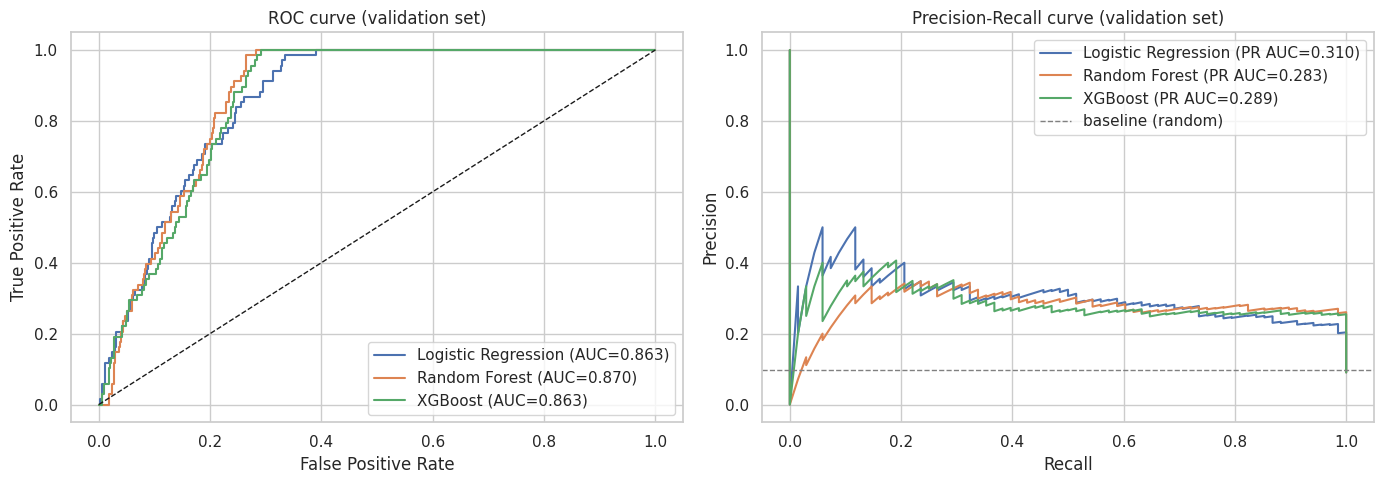

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, res in val_results.items():
    fpr, tpr, _ = roc_curve(y_val, res["proba"])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={res['roc_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1)
axes[0].set_title("ROC curve (validation set)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

for name, res in val_results.items():
    prec, rec, _ = precision_recall_curve(y_val, res["proba"])
    axes[1].plot(rec, prec, label=f"{name} (PR AUC={res['pr_auc']:.3f})")
axes[1].axhline(fraud_rate, color="gray", linestyle="--", linewidth=1, label="baseline (random)")
axes[1].set_title("Precision-Recall curve (validation set)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()
plt.tight_layout()
plt.show()


### Threshold selection

The SRS's proposed MVP gate (ML03) is **recall ≥ 80% and precision ≥ 30%**. For each model,
the code below scans thresholds on the validation set and picks the lowest threshold that
still clears recall ≥ 80%, then checks whether precision at that point also clears 30%.


In [ ]:
def best_threshold_for_recall(y_true, proba, min_recall=0.80):
    thresholds = np.linspace(0.01, 0.99, 99)
    best = None
    for t in thresholds:
        preds = (proba >= t).astype(int)
        r = recall_score(y_true, preds, zero_division=0)
        p = precision_score(y_true, preds, zero_division=0)
        if r >= min_recall:
            if best is None or t > best["threshold"]:
                best = {"threshold": t, "precision": p, "recall": r}
    return best

threshold_rows = []
for name, res in val_results.items():
    best = best_threshold_for_recall(y_val, res["proba"], min_recall=0.80)
    if best:
        gate_pass = best["precision"] >= 0.30
        threshold_rows.append({
            "Model": name, "Threshold": round(best["threshold"], 2),
            "Precision @ recall>=80%": round(best["precision"], 3),
            "Recall @ threshold": round(best["recall"], 3),
            "Gate (P>=30%, R>=80%) met?": "YES" if gate_pass else "no",
        })
    else:
        threshold_rows.append({
            "Model": name, "Threshold": "n/a",
            "Precision @ recall>=80%": "n/a", "Recall @ threshold": "n/a",
            "Gate (P>=30%, R>=80%) met?": "no recall>=80% achievable",
        })

threshold_df = pd.DataFrame(threshold_rows)
threshold_df


,Model,Threshold,Precision @ recall>=80%,Recall @ threshold,"Gate (P>=30%, R>=80%) met?"
0,Logistic Regression,0.43,0.250,0.824,no
1,Random Forest,0.48,0.281,0.809,no
2,XGBoost,0.20,0.257,0.809,no


**Reading this table against SRS ML03:** if no model reaches the gate on this validation set, that is a valid and expected outcome to report — the SRS itself anticipates this ("the model shall be marked demonstration-only and the result documented; targets shall not be silently relaxed"). Whatever the table above shows, carry it into the report honestly rather than picking a different metric after the fact.

## 9. Final model selection and test-set evaluation

The model with the strongest validation PR AUC (the standard metric for imbalanced
classification) is selected and evaluated **once** on the untouched test partition, using the
fixed 0.40 / 0.70 band thresholds proposed in SRS ML04 (not re-tuned on the test set).


Selected model (highest validation PR AUC): Logistic Regression

Test set size: 750 | fraud cases in test set: 63

--- Test set metrics @ threshold 0.50 ---
Accuracy:  0.799  (a dummy 'always legitimate' model would score 0.916 here — accuracy alone is not a meaningful comparison point on this imbalanced data)
Precision: 0.258
Recall:    0.746
F1:        0.384
ROC AUC:   0.881
PR AUC:    0.421


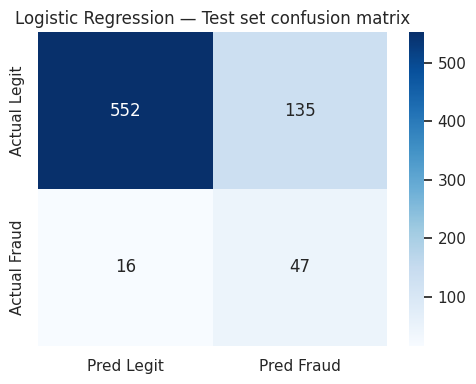


⚠ SRS ML03 data-sufficiency note: the test set contains only 63 confirmed fraud cases, below the proposed minimum of 100. Per ML03 this model should be marked DEMONSTRATION-ONLY rather than production-ready, regardless of whether the precision/recall numbers above clear the gate.


In [ ]:
best_model_name = comparison_df.iloc[0]["Model"]
best_pipe = models[best_model_name]
print(f"Selected model (highest validation PR AUC): {best_model_name}")

test_proba = best_pipe.predict_proba(X_test)[:, 1]
test_preds_default = (test_proba >= 0.5).astype(int)

print(f"\nTest set size: {len(X_test)} | fraud cases in test set: {y_test.sum()}")
print("\n--- Test set metrics @ threshold 0.50 ---")
print(f"Accuracy:  {accuracy_score(y_test, test_preds_default):.3f}  "
      f"(a dummy 'always legitimate' model would score {1 - y_test.mean():.3f} here — "
      f"accuracy alone is not a meaningful comparison point on this imbalanced data)")
print(f"Precision: {precision_score(y_test, test_preds_default, zero_division=0):.3f}")
print(f"Recall:    {recall_score(y_test, test_preds_default, zero_division=0):.3f}")
print(f"F1:        {f1_score(y_test, test_preds_default, zero_division=0):.3f}")
print(f"ROC AUC:   {roc_auc_score(y_test, test_proba):.3f}")
print(f"PR AUC:    {average_precision_score(y_test, test_proba):.3f}")

cm = confusion_matrix(y_test, test_preds_default)
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Pred Legit", "Pred Fraud"],
            yticklabels=["Actual Legit", "Actual Fraud"], ax=ax)
ax.set_title(f"{best_model_name} — Test set confusion matrix")
plt.tight_layout()
plt.show()

if y_test.sum() < 100:
    print(f"\n⚠ SRS ML03 data-sufficiency note: the test set contains only {y_test.sum()} "
          f"confirmed fraud cases, below the proposed minimum of 100. Per ML03 this model "
          f"should be marked DEMONSTRATION-ONLY rather than production-ready, regardless of "
          f"whether the precision/recall numbers above clear the gate.")


### Visualization gallery — chart types 24–26 (interactive, model-based)

The final three chart types from your list need trained model output, so they're built here
rather than in the EDA section.


In [ ]:
# 24. ROC Curve — Evaluate classification model
fig = go.Figure()
for name, res in val_results.items():
    fpr, tpr, _ = roc_curve(y_val, res["proba"])
    fig.add_trace(go.Scatter(x=fpr, y=tpr, mode="lines", name=f"{name} (AUC={res['roc_auc']:.3f})"))
fig.add_trace(go.Scatter(x=[0, 1], y=[0, 1], mode="lines", line=dict(dash="dash", color="gray"), name="Random"))
fig.update_layout(title="24. ROC Curve — model comparison on the validation set",
                   xaxis_title="False Positive Rate", yaxis_title="True Positive Rate")
fig.show()


In [ ]:
# 25. Precision-Recall Curve — Evaluate fraud detection performance
fig = go.Figure()
for name, res in val_results.items():
    prec, rec, _ = precision_recall_curve(y_val, res["proba"])
    fig.add_trace(go.Scatter(x=rec, y=prec, mode="lines", name=f"{name} (PR AUC={res['pr_auc']:.3f})"))
fig.add_hline(y=fraud_rate, line_dash="dash", line_color="gray", annotation_text="random baseline")
fig.update_layout(title="25. Precision-Recall Curve — model comparison on the validation set",
                   xaxis_title="Recall", yaxis_title="Precision")
fig.show()


In [ ]:
# 26. Confusion Matrix — Show classification results
cm_test = confusion_matrix(y_test, test_preds_default)
fig = px.imshow(cm_test, text_auto=True, color_continuous_scale="Blues",
                 x=["Pred Legit", "Pred Fraud"], y=["Actual Legit", "Actual Fraud"],
                 title=f"26. Confusion Matrix — {best_model_name}, test set")
fig.show()


## 10. Feature importance (explainability, SRS ML04)

ML04 requires identifying up to three contributing features per prediction using a documented
method, without implying causal proof. Here we report **global** feature importance for the
selected model as a model-level explanation (a full per-transaction explanation service is out
of scope for this static project).


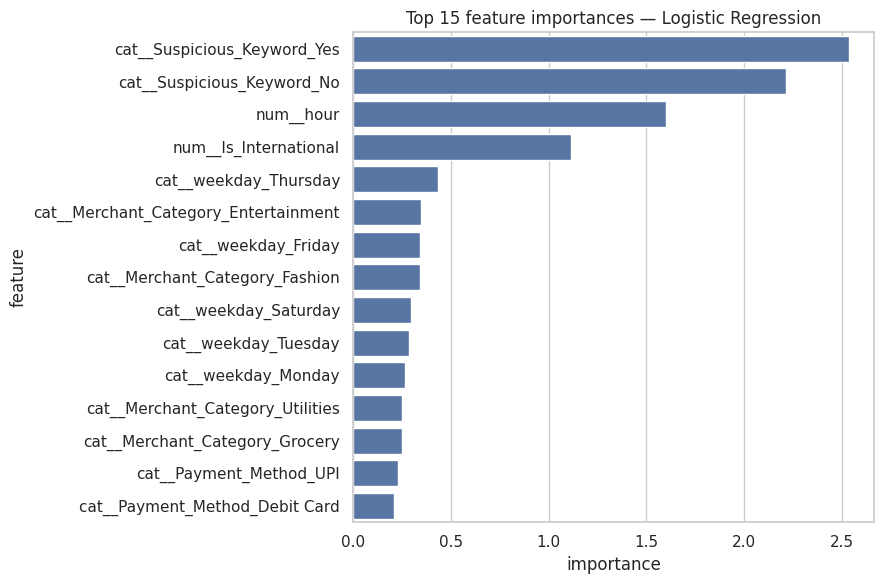

Top 3 contributing features (global, not per-transaction causal proof):
                    feature  importance
cat__Suspicious_Keyword_Yes    2.538929
 cat__Suspicious_Keyword_No    2.215810
                  num__hour    1.602924


In [ ]:
clf = best_pipe.named_steps["clf"]
prep = best_pipe.named_steps["prep"]
feature_names = prep.get_feature_names_out()

if hasattr(clf, "feature_importances_"):
    importances = clf.feature_importances_
elif hasattr(clf, "coef_"):
    importances = np.abs(clf.coef_[0])
else:
    importances = None

if importances is not None:
    imp_df = pd.DataFrame({"feature": feature_names, "importance": importances})
    imp_df = imp_df.sort_values("importance", ascending=False).head(15)

    fig, ax = plt.subplots(figsize=(9, 6))
    sns.barplot(x="importance", y="feature", data=imp_df, ax=ax, color="#4C72B0")
    ax.set_title(f"Top 15 feature importances — {best_model_name}")
    plt.tight_layout()
    plt.show()

    print("Top 3 contributing features (global, not per-transaction causal proof):")
    print(imp_df.head(3)[["feature", "importance"]].to_string(index=False))


## 11. Score the full dataset and assign risk bands (SRS ML04)

The selected model is used to score every transaction in the dataset (train+val+test, since
this is a static demo dataset rather than a live feed). Risk bands follow the SRS ML04 demo
defaults: **Low** < 0.40, **Medium** 0.40–0.70, **High** ≥ 0.70. This scored file is the
direct input to the Power BI dashboard.


In [ ]:
full_X = df_sorted[feature_cols]
df_sorted["risk_score"] = best_pipe.predict_proba(full_X)[:, 1]

def band(score):
    if score >= 0.70:
        return "High"
    elif score >= 0.40:
        return "Medium"
    return "Low"

df_sorted["risk_band"] = df_sorted["risk_score"].apply(band)
df_sorted["predicted_fraud"] = (df_sorted["risk_score"] >= 0.5).astype(int)
df_sorted["split"] = np.where(
    df_sorted["Transaction_Date"] <= train_df["Transaction_Date"].max(), "train",
    np.where(df_sorted["Transaction_Date"] <= val_df["Transaction_Date"].max(), "validation", "test")
)
df_sorted["model_version"] = f"{best_model_name.replace(' ', '_').lower()}_v1"
df_sorted["alert_flag"] = (df_sorted["risk_band"] == "High").astype(int)

print(df_sorted["risk_band"].value_counts())
df_sorted[["Transaction_ID", "Transaction_Date", "Transaction_Amount", "Fraudulent",
           "risk_score", "risk_band", "predicted_fraud", "alert_flag", "split"]].head(10)


risk_band
Low       3373
Medium     969
High       658
Name: count, dtype: int64


,Transaction_ID,Transaction_Date,Transaction_Amount,Fraudulent,risk_score,risk_band,predicted_fraud,alert_flag,split
0,T103438,2023-01-01 02:16:00,210.69,0,0.994029,High,1,1,train
1,T104159,2023-01-01 05:46:00,66.73,0,0.982504,High,1,1,train
2,T102971,2023-01-01 09:06:00,14.24,0,0.170265,Low,0,0,train
3,T102322,2023-01-01 11:34:00,74.90,0,0.961524,High,1,1,train
4,T104734,2023-01-01 11:41:00,45.04,0,0.172017,Low,0,0,train
5,T103896,2023-01-01 11:51:00,12.67,0,0.123465,Low,0,0,train
6,T100514,2023-01-01 12:08:00,3.70,0,0.103556,Low,0,0,train
7,T101258,2023-01-01 14:42:00,5.31,0,0.063050,Low,0,0,train
8,T102688,2023-01-01 18:05:00,54.32,0,0.026105,Low,0,0,train
9,T101230,2023-01-01 18:56:00,179.62,0,0.026189,Low,0,0,train


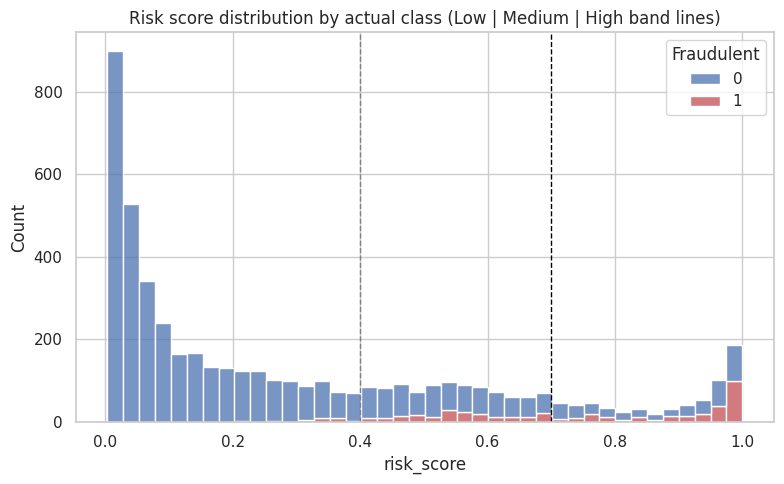

In [ ]:
fig, ax = plt.subplots()
sns.histplot(data=df_sorted, x="risk_score", hue="Fraudulent", bins=40,
             multiple="stack", palette=["#4C72B0", "#C44E52"])
ax.axvline(0.40, color="gray", linestyle="--", linewidth=1)
ax.axvline(0.70, color="black", linestyle="--", linewidth=1)
ax.set_title("Risk score distribution by actual class (Low | Medium | High band lines)")
plt.tight_layout()
plt.show()


## 12. Export deliverables for the dashboard and report

In [ ]:
dashboard_cols = [
    "Transaction_ID", "Customer_ID", "Transaction_Date", "Transaction_Amount",
    "Merchant_Category", "Payment_Method", "Device_Type", "Location",
    "Is_International", "Previous_Transactions", "Average_Spend", "Account_Age_Days",
    "Suspicious_Keyword", "hour", "weekday", "amount_vs_avg_ratio",
    "Fraudulent", "risk_score", "risk_band", "predicted_fraud", "alert_flag",
    "split", "model_version",
]
scored_export = df_sorted[dashboard_cols].rename(columns={"Fraudulent": "actual_fraud"})
scored_export.to_csv("scored_transactions.csv", index=False)

comparison_df.to_csv("model_comparison_validation.csv", index=False)
threshold_df.to_csv("threshold_gate_results.csv", index=False)

if importances is not None:
    imp_df.to_csv("feature_importance.csv", index=False)

test_metrics_summary = pd.DataFrame([{
    "Model": best_model_name,
    "Test_Precision": round(precision_score(y_test, test_preds_default, zero_division=0), 3),
    "Test_Recall": round(recall_score(y_test, test_preds_default, zero_division=0), 3),
    "Test_F1": round(f1_score(y_test, test_preds_default, zero_division=0), 3),
    "Test_ROC_AUC": round(roc_auc_score(y_test, test_proba), 3),
    "Test_PR_AUC": round(average_precision_score(y_test, test_proba), 3),
    "Test_Set_Size": len(X_test),
    "Test_Fraud_Cases": int(y_test.sum()),
    "Gate_Data_Sufficient (>=100 fraud cases)": "YES" if y_test.sum() >= 100 else "NO",
}])
test_metrics_summary.to_csv("final_test_metrics.csv", index=False)

print("Exported files:")
for f in ["scored_transactions.csv", "model_comparison_validation.csv",
          "threshold_gate_results.csv", "feature_importance.csv", "final_test_metrics.csv"]:
    print(" -", f)


Exported files:
 - scored_transactions.csv
 - model_comparison_validation.csv
 - threshold_gate_results.csv
 - feature_importance.csv
 - final_test_metrics.csv


## 13. Summary

- **Data:** 5,000 static, pre-cleaned transactions (~9.6% fraud rate), Jan 2023–Feb 2024.
- **Models compared:** Logistic Regression, Random Forest, XGBoost — trained on a
  chronological split with no leakage of identifiers, labels, or future events.
- **Selection:** best model chosen by validation PR AUC; final numbers reported once on the
  held-out test set only.
- **Gate check:** results are checked against the SRS's proposed MVP gate (recall ≥ 80%,
  precision ≥ 30%, ≥ 100 confirmed fraud cases in the held-out set) and reported honestly,
  including a demonstration-only flag if the data-sufficiency condition isn't met.
- **Outputs:** `scored_transactions.csv` (feeds the Power BI dashboard),
  `model_comparison_validation.csv`, `threshold_gate_results.csv`, `feature_importance.csv`,
  and `final_test_metrics.csv` (feed the written report).

See the accompanying **Report** for the full write-up, explicit scope deviations from the
original SRS, and the **Power BI dashboard** for the interactive investigation view.
